In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv('Walmart.csv')
df

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667


In [6]:
# Get unique stores
stores = df['Store'].unique()
print(f"Number of stores: {len(stores)}")
print(f"Store IDs: {stores}")

# Create a dictionary to store data for each store
store_data = {}
for store in stores:
    store_data[store] = df[df['Store'] == store].copy()
    print(f"Store {store}: {len(store_data[store])} records")

# Alternative: Create individual DataFrames for each store
# This creates separate variables for each store
for store in stores:
    globals()[f'store_{store}_data'] = df[df['Store'] == store].copy()

print("\nData split completed! You can access:")
print("- store_data[store_id] for dictionary access")
print("- store_1_data, store_2_data, etc. for individual DataFrames")

Number of stores: 45
Store IDs: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45]
Store 1: 143 records
Store 2: 143 records
Store 3: 143 records
Store 4: 143 records
Store 5: 143 records
Store 6: 143 records
Store 7: 143 records
Store 8: 143 records
Store 9: 143 records
Store 10: 143 records
Store 11: 143 records
Store 12: 143 records
Store 13: 143 records
Store 14: 143 records
Store 15: 143 records
Store 16: 143 records
Store 17: 143 records
Store 18: 143 records
Store 19: 143 records
Store 20: 143 records
Store 21: 143 records
Store 22: 143 records
Store 23: 143 records
Store 24: 143 records
Store 25: 143 records
Store 26: 143 records
Store 27: 143 records
Store 28: 143 records
Store 29: 143 records
Store 30: 143 records
Store 31: 143 records
Store 32: 143 records
Store 33: 143 records
Store 34: 143 records
Store 35: 143 records
Store 36: 143 records
Store 37: 143 records
Store 38: 143 records
Sto

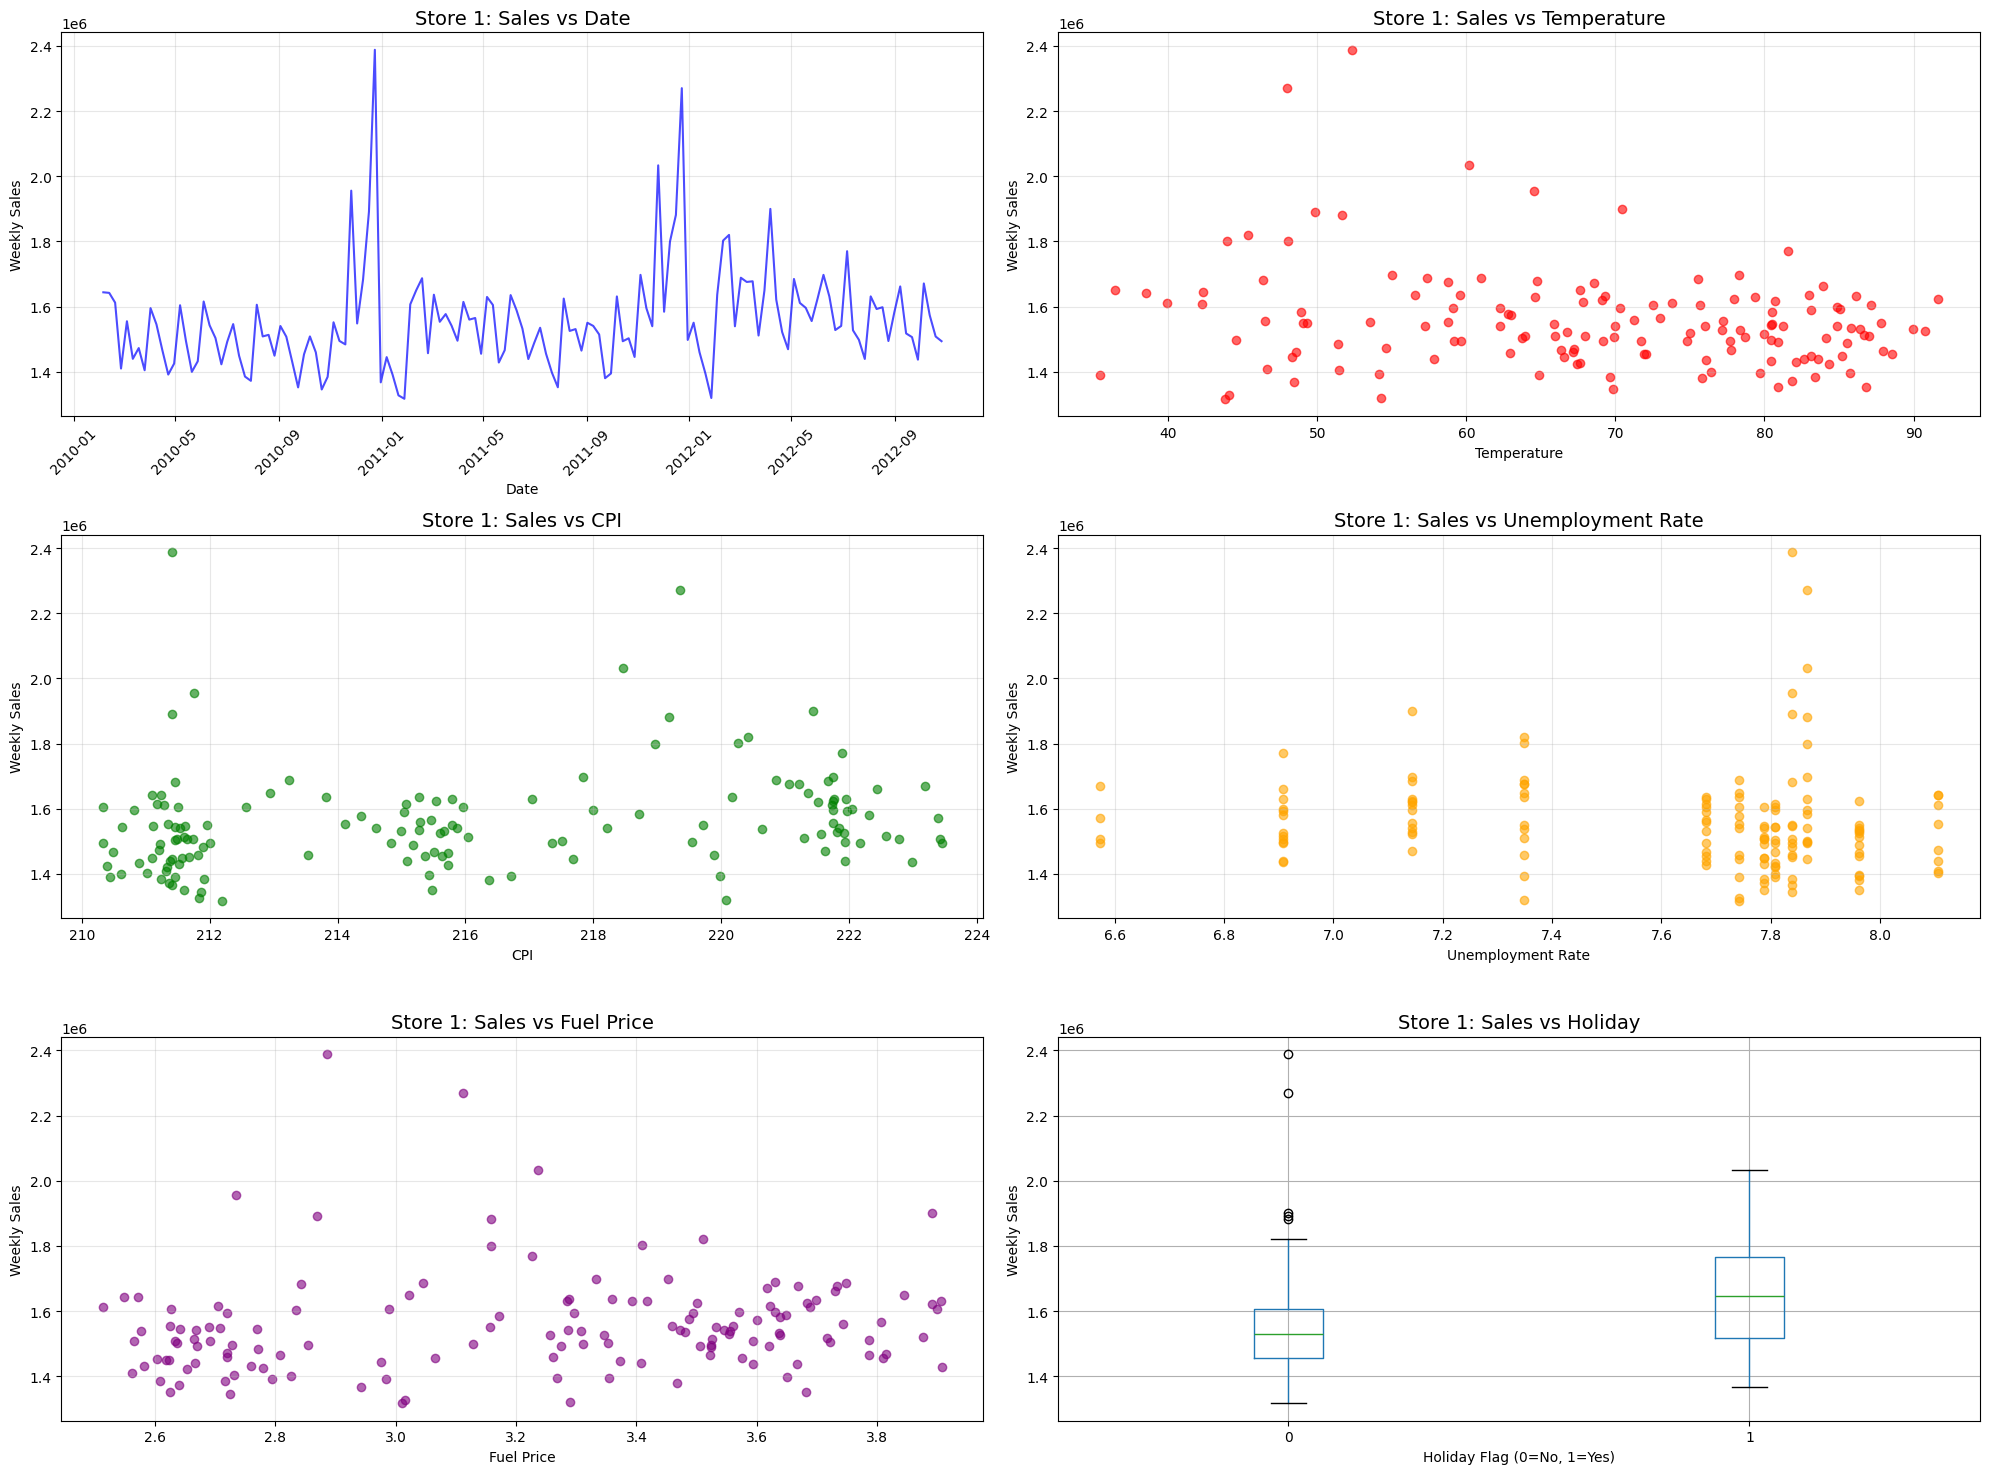

Store 1 Sales Statistics:
Total records: 143
Date range: 2010-02-05 00:00:00 to 2012-10-26 00:00:00
Average weekly sales: $1,555,264.40
Holiday vs Non-holiday sales:
              count          mean
Holiday_Flag                     
0               133  1.546957e+06
1                10  1.665748e+06


In [8]:
# Get Store 1 data
store_1 = store_data[1].copy()

# Convert Date column to datetime if it's not already
if 'Date' in store_1.columns:
    store_1['Date'] = pd.to_datetime(store_1['Date'], dayfirst=True)


# Create subplots for all visualizations
plt.figure(figsize=(20, 15))

# 1. Sales vs Date
plt.subplot(3, 2, 1)
plt.plot(store_1['Date'], store_1['Weekly_Sales'], color='blue', alpha=0.7)
plt.title('Store 1: Sales vs Date', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

# 2. Sales vs Temperature
plt.subplot(3, 2, 2)
plt.scatter(store_1['Temperature'], store_1['Weekly_Sales'], alpha=0.6, color='red')
plt.title('Store 1: Sales vs Temperature', fontsize=14)
plt.xlabel('Temperature')
plt.ylabel('Weekly Sales')
plt.grid(True, alpha=0.3)

# 3. Sales vs CPI
plt.subplot(3, 2, 3)
plt.scatter(store_1['CPI'], store_1['Weekly_Sales'], alpha=0.6, color='green')
plt.title('Store 1: Sales vs CPI', fontsize=14)
plt.xlabel('CPI')
plt.ylabel('Weekly Sales')
plt.grid(True, alpha=0.3)

# 4. Sales vs Unemployment Rate
plt.subplot(3, 2, 4)
plt.scatter(store_1['Unemployment'], store_1['Weekly_Sales'], alpha=0.6, color='orange')
plt.title('Store 1: Sales vs Unemployment Rate', fontsize=14)
plt.xlabel('Unemployment Rate')
plt.ylabel('Weekly Sales')
plt.grid(True, alpha=0.3)

# 5. Sales vs Fuel Price
plt.subplot(3, 2, 5)
plt.scatter(store_1['Fuel_Price'], store_1['Weekly_Sales'], alpha=0.6, color='purple')
plt.title('Store 1: Sales vs Fuel Price', fontsize=14)
plt.xlabel('Fuel Price')
plt.ylabel('Weekly Sales')
plt.grid(True, alpha=0.3)

# 6. Sales vs Holiday (Box plot)
plt.subplot(3, 2, 6)
store_1.boxplot(column='Weekly_Sales', by='Holiday_Flag', ax=plt.gca())
plt.title('Store 1: Sales vs Holiday', fontsize=14)
plt.xlabel('Holiday Flag (0=No, 1=Yes)')
plt.ylabel('Weekly Sales')
plt.suptitle('')  # Remove automatic title

plt.tight_layout()
plt.show()

# Print some basic statistics
print("Store 1 Sales Statistics:")
print(f"Total records: {len(store_1)}")
print(f"Date range: {store_1['Date'].min()} to {store_1['Date'].max()}")
print(f"Average weekly sales: ${store_1['Weekly_Sales'].mean():,.2f}")
print(f"Holiday vs Non-holiday sales:")
print(store_1.groupby('Holiday_Flag')['Weekly_Sales'].agg(['count', 'mean']))

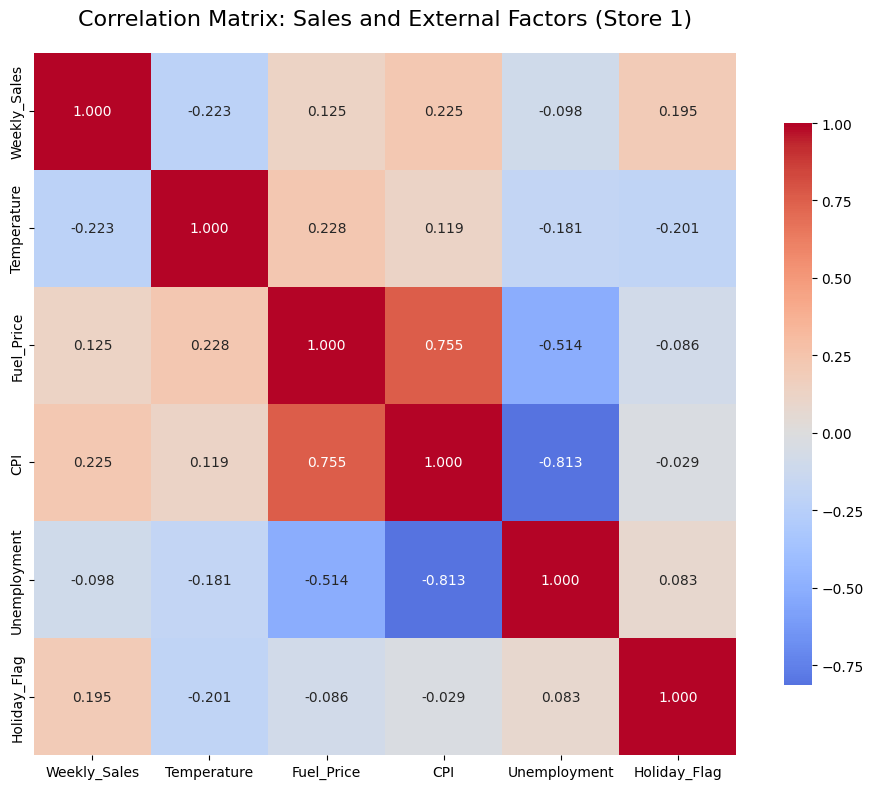

Correlation Matrix:
              Weekly_Sales  Temperature  Fuel_Price    CPI  Unemployment  \
Weekly_Sales         1.000       -0.223       0.125  0.225        -0.098   
Temperature         -0.223        1.000       0.228  0.119        -0.181   
Fuel_Price           0.125        0.228       1.000  0.755        -0.514   
CPI                  0.225        0.119       0.755  1.000        -0.813   
Unemployment        -0.098       -0.181      -0.514 -0.813         1.000   
Holiday_Flag         0.195       -0.201      -0.086 -0.029         0.083   

              Holiday_Flag  
Weekly_Sales         0.195  
Temperature         -0.201  
Fuel_Price          -0.086  
CPI                 -0.029  
Unemployment         0.083  
Holiday_Flag         1.000  

Correlations with Weekly Sales:
CPI            :   0.225
Temperature    :  -0.223
Holiday_Flag   :   0.195
Fuel_Price     :   0.125
Unemployment   :  -0.098


In [9]:
# Create correlation matrix for specified variables
correlation_vars = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Holiday_Flag']

# Select only the specified columns from store_1 data
correlation_data = store_1[correlation_vars]

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Create the correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, 
            annot=True,           # Show correlation values
            cmap='coolwarm',      # Color scheme
            center=0,             # Center colormap at 0
            square=True,          # Make cells square
            fmt='.3f',            # Format to 3 decimal places
            cbar_kws={'shrink': 0.8})

plt.title('Correlation Matrix: Sales and External Factors (Store 1)', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

# Print correlation matrix as table
print("Correlation Matrix:")
print("=" * 60)
print(correlation_matrix.round(3))

# Print strongest correlations with Weekly_Sales
print("\nCorrelations with Weekly Sales:")
print("=" * 40)
sales_correlations = correlation_matrix['Weekly_Sales'].drop('Weekly_Sales').sort_values(key=abs, ascending=False)
for var, corr in sales_correlations.items():
    print(f"{var:<15}: {corr:>7.3f}")